In [ ]:
import pandas as pd
import numpy as np


In [ ]:
students = pd.read_csv("/studentInfo.csv")

print(students.shape)
print(students.head())
print(students["final_result"].value_counts())

(32593, 12)
  code_module code_presentation  id_student gender                region  \
0         AAA             2013J       11391      M   East Anglian Region   
1         AAA             2013J       28400      F              Scotland   
2         AAA             2013J       30268      F  North Western Region   
3         AAA             2013J       31604      F     South East Region   
4         AAA             2013J       32885      F  West Midlands Region   

       highest_education imd_band age_band  num_of_prev_attempts  \
0       HE Qualification  90-100%     55<=                     0   
1       HE Qualification   20-30%    35-55                     0   
2  A Level or Equivalent   30-40%    35-55                     0   
3  A Level or Equivalent   50-60%    35-55                     0   
4     Lower Than A Level   50-60%     0-35                     0   

   studied_credits disability final_result  
0              240          N         Pass  
1               60          N   

In [ ]:
!sed 's/"//g' /studentVle.csv > /vle_clean.csv

clicks = pd.read_csv("/vle_clean.csv")

print(clicks.shape)
print(clicks.dtypes)

(10655280, 6)
code_module          object
code_presentation    object
id_student            int64
id_site               int64
date                  int64
sum_click             int64
dtype: object


In [ ]:
total = clicks.groupby("id_student")["sum_click"].sum()

print(total.describe())

count    26074.000000
mean      1518.949873
std       1935.994635
min          1.000000
25%        298.000000
50%        824.000000
75%       2018.000000
max      28615.000000
Name: sum_click, dtype: float64


In [ ]:
keys = ["code_module", "code_presentation", "id_student"]

early = clicks[clicks["date"] <= 27].copy()

early_total = (
    early.groupby(keys)["sum_click"]
    .sum()
    .reset_index(name="early_clicks")
)

print(early_total.head())
print(early_total.shape)

  code_module code_presentation  id_student  early_clicks
0         AAA             2013J       11391           401
1         AAA             2013J       28400           550
2         AAA             2013J       30268           281
3         AAA             2013J       31604           478
4         AAA             2013J       32885           567
(28774, 4)


In [ ]:
feat = (
    early.groupby(keys)
    .agg(
        early_active_days=("date", "nunique"),
        early_sites=("id_site", "nunique")
    )
    .reset_index()
)

print(feat.head())
print(feat.shape)

  code_module code_presentation  id_student  early_active_days  early_sites
0         AAA             2013J       11391                  8           24
1         AAA             2013J       28400                 18           30
2         AAA             2013J       30268                 12           22
3         AAA             2013J       31604                 21           30
4         AAA             2013J       32885                 24           34
(28774, 5)


In [ ]:
early["half"] = np.where(
    early["date"] <= 13,
    "clicks_wk1_2",
    "clicks_wk3_4"
)

halves = (
    early.pivot_table(
        index=keys,
        columns="half",
        values="sum_click",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

print(halves.head())
print(halves.shape)

half code_module code_presentation  id_student  clicks_wk1_2  clicks_wk3_4
0            AAA             2013J       11391           301           100
1            AAA             2013J       28400           456            94
2            AAA             2013J       30268           281             0
3            AAA             2013J       31604           345           133
4            AAA             2013J       32885           472            95
(28774, 5)


In [ ]:
data = (
    students
    .merge(early_total, on=keys, how="left")
    .merge(feat, on=keys, how="left")
    .merge(halves, on=keys, how="left")
)

new_cols = [
    "early_clicks",
    "early_active_days",
    "early_sites",
    "clicks_wk1_2",
    "clicks_wk3_4"
]

data[new_cols] = data[new_cols].fillna(0)

data["at_risk"] = data["final_result"].isin(
    ["Fail", "Withdrawn"]
).astype(int)

print(data.shape)
print(data[new_cols + ["at_risk"]].head())

(32593, 18)
   early_clicks  early_active_days  early_sites  clicks_wk1_2  clicks_wk3_4  \
0         401.0                8.0         24.0         301.0         100.0   
1         550.0               18.0         30.0         456.0          94.0   
2         281.0               12.0         22.0         281.0           0.0   
3         478.0               21.0         30.0         345.0         133.0   
4         567.0               24.0         34.0         472.0          95.0   

   at_risk  
0        0  
1        0  
2        1  
3        0  
4        0  


In [ ]:
print(
    data.groupby("final_result")["early_clicks"]
    .agg(["median", "mean"])
    .round(1)
)

              median   mean
final_result               
Distinction    388.0  558.7
Fail           130.0  220.7
Pass           275.0  402.5
Withdrawn       58.0  168.2


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X = np.log1p(data[["early_clicks"]])
y = data["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("At-risk share:", round(y.mean(), 3))
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("F1:", round(f1_score(y_test, pred), 3))

At-risk share: 0.528
Accuracy: 0.67
F1: 0.666


In [ ]:
from sklearn.ensemble import RandomForestClassifier

X = data[
    [
        "early_clicks",
        "early_active_days",
        "early_sites",
        "clicks_wk1_2",
        "clicks_wk3_4"
    ]
]

y = data["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("F1:", round(f1_score(y_test, rf_pred), 3))

Accuracy: 0.651
F1: 0.659


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

X = data[
    [
        "early_clicks",
        "early_active_days",
        "early_sites",
        "clicks_wk1_2",
        "clicks_wk3_4"
    ]
]

y = data["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

nn_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    max_iter=300,
    random_state=42,
    early_stopping=True
)

nn_model.fit(X_train_scaled, y_train)

nn_pred = nn_model.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, nn_pred), 3))
print("F1:", round(f1_score(y_test, nn_pred), 3))

Accuracy: 0.688
F1: 0.697


In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    nn_model,
    X_test_scaled,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1"
)

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

print(importance)

             feature  importance
0       early_clicks    0.052094
1  early_active_days    0.024487
2        early_sites    0.005495
3       clicks_wk1_2    0.001521
4       clicks_wk3_4   -0.000510


In [ ]:
!pip -q install shap

In [ ]:
import shap

explainer = shap.KernelExplainer(
    nn_model.predict_proba,
    X_train_scaled[:100]
)

shap_values = explainer.shap_values(
    X_test_scaled[:100]
)

print("SHAP analysis completed.")

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP analysis completed.


In [ ]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(100, 5, 2)


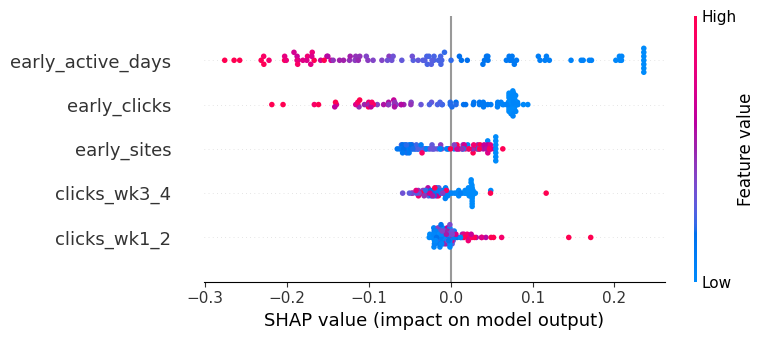

In [ ]:
shap_values_risk = shap_values[:, :, 1]

shap.summary_plot(
    shap_values_risk,
    X_test_scaled[:100],
    feature_names=X.columns
)

SHAP Analysis Interpretation

The SHAP analysis showed that lower activity during the first four weeks pushed the model more strongly toward predicting a student as at risk.
Fewer active days and fewer early clicks had the strongest influence on the predictions, while the other features had smaller effects.
These findings show associations in the data and do not prove that low activity causes students to fail or withdraw.

Model Performance Comparison

Three machine learning models were evaluated using accuracy and F1-score. The neural network achieved the best performance, with an accuracy of 0.688 and an F1-score of 0.697. Logistic regression achieved an accuracy of 0.670 and an F1-score of 0.666, while random forest achieved 0.651 accuracy and 0.659 F1-score.

In [ ]:
from google.colab import drive
drive.mount('/content/drive2')

Mounted at /content/drive2


In [ ]:
import os

folder = "/content/drive2/MyDrive/OULAD_Project"
print(os.listdir(folder))

['studentVle.csv', 'studentInfo.csv']


In [ ]:
import os

folder = "/content/drive2/MyDrive/OULAD_Project"

print("Files found:", os.listdir(folder))
print("studentInfo.csv exists:", os.path.exists(folder + "/studentInfo.csv"))
print("studentVle.csv exists:", os.path.exists(folder + "/studentVle.csv"))

Files found: ['studentVle.csv', 'studentInfo.csv']
studentInfo.csv exists: True
studentVle.csv exists: True


In [ ]:
import pandas as pd

folder = "/content/drive2/MyDrive/OULAD_Project"

studentInfo = pd.read_csv(folder + "/studentInfo.csv")
studentVle = pd.read_csv(folder + "/studentVle.csv")

print("Student Info shape:", studentInfo.shape)
print("Student VLE shape:", studentVle.shape)

display(studentInfo.head())
display(studentVle.head())

Student Info shape: (32593, 12)
Student VLE shape: (10655280, 6)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [ ]:
print("Student Info:", studentInfo.shape)
print("Student VLE:", studentVle.shape)

print("\nColumns in studentInfo:")
print(studentInfo.columns.tolist())

print("\nColumns in studentVle:")
print(studentVle.columns.tolist())

Student Info: (32593, 12)
Student VLE: (10655280, 6)

Columns in studentInfo:
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

Columns in studentVle:
['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']


In [ ]:
import pandas as pd

# Prepare student information
df = studentInfo.copy()

# Create target: 1 = At risk, 0 = Not at risk
df["at_risk"] = df["final_result"].isin(
    ["Fail", "Withdrawn"]
).astype(int)

print("Student records:", len(df))
print("\nTarget distribution:")
print(df["at_risk"].value_counts())
print("\nTarget percentages:")
print((df["at_risk"].value_counts(normalize=True) * 100).round(2))

Student records: 32593

Target distribution:
at_risk
1    17208
0    15385
Name: count, dtype: int64

Target percentages:
at_risk
1    52.8
0    47.2
Name: proportion, dtype: float64


In [ ]:
# Select activity from the first 4 weeks
early_vle = studentVle[studentVle["date"] <= 27].copy()

# Summarize early activity for each student
early_features = early_vle.groupby("id_student").agg(
    early_clicks=("sum_click", "sum"),
    early_active_days=("date", "nunique"),
    early_sites=("id_site", "nunique")
).reset_index()

print("Early activity records:", len(early_vle))
print("Students with early activity:", len(early_features))
display(early_features.head())

Early activity records: 2801311
Students with early activity: 25692


,id_student,early_clicks,early_active_days,early_sites
0,6516,799,27,33
1,8462,350,19,79
2,11391,401,8,24
3,23629,53,6,7
4,23698,365,30,21


In [ ]:
# Merge early activity features with student information
data = df.merge(
    early_features,
    left_on="id_student",
    right_on="id_student",
    how="left"
)

# Students without recorded early activity get zero
feature_cols = [
    "early_clicks",
    "early_active_days",
    "early_sites"
]

data[feature_cols] = data[feature_cols].fillna(0)

print("Combined dataset shape:", data.shape)
print("Missing early activity values:")
print(data[feature_cols].isna().sum())
display(data[["id_student", "final_result", "at_risk"] + feature_cols].head())

Combined dataset shape: (32593, 16)
Missing early activity values:
early_clicks         0
early_active_days    0
early_sites          0
dtype: int64


,id_student,final_result,at_risk,early_clicks,early_active_days,early_sites
0,11391,Pass,0,401.0,8.0,24.0
1,28400,Pass,0,550.0,18.0,30.0
2,30268,Withdrawn,1,281.0,12.0,22.0
3,31604,Pass,0,478.0,21.0,30.0
4,32885,Pass,0,567.0,24.0,34.0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select input features and target
X = data[
    ["early_clicks", "early_active_days", "early_sites"]
]
y = data["at_risk"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 26074
Testing records: 6519


In [ ]:
# Create and train the Neural Network
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=42,
    early_stopping=True
)

model.fit(X_train_scaled, y_train)

# Predict on the test data
y_pred_nn = model.predict(X_test_scaled)

print("Neural Network training completed!")
print("Predictions created:", len(y_pred_nn))

Neural Network training completed!
Predictions created: 6519


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_nn), 4))
print("Precision:", round(precision_score(y_test, y_pred_nn), 4))
print("Recall:", round(recall_score(y_test, y_pred_nn), 4))
print("F1-score:", round(f1_score(y_test, y_pred_nn), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

Accuracy: 0.6519
Precision: 0.6868
Recall: 0.6264
F1-score: 0.6552

Confusion Matrix:
[[2094  983]
 [1286 2156]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.68      0.65      3077
           1       0.69      0.63      0.66      3442

    accuracy                           0.65      6519
   macro avg       0.65      0.65      0.65      6519
weighted avg       0.66      0.65      0.65      6519



In [ ]:
# Create weekly activity features from the existing VLE data

vle_w12 = studentVle[
    (studentVle["date"] >= 0) &
    (studentVle["date"] <= 13)
].groupby("id_student")["sum_click"].sum().rename("clicks_wk1_2")

vle_w34 = studentVle[
    (studentVle["date"] >= 14) &
    (studentVle["date"] <= 27)
].groupby("id_student")["sum_click"].sum().rename("clicks_wk3_4")

# Add weekly features to the combined dataset
data = data.drop(
    columns=["clicks_wk1_2", "clicks_wk3_4"],
    errors="ignore"
)

data = data.join(vle_w12, on="id_student")
data = data.join(vle_w34, on="id_student")

data[["clicks_wk1_2", "clicks_wk3_4"]] = data[
    ["clicks_wk1_2", "clicks_wk3_4"]
].fillna(0)

print("Dataset shape:", data.shape)
display(data[[
    "id_student", "early_clicks",
    "clicks_wk1_2", "clicks_wk3_4", "at_risk"
]].head())

Dataset shape: (32593, 18)


,id_student,early_clicks,clicks_wk1_2,clicks_wk3_4,at_risk
0,11391,401.0,203.0,100.0,0
1,28400,550.0,241.0,94.0,0
2,30268,281.0,179.0,0.0,1
3,31604,478.0,176.0,133.0,0
4,32885,567.0,177.0,95.0,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Select five features
feature_cols = [
    "early_clicks",
    "early_active_days",
    "early_sites",
    "clicks_wk1_2",
    "clicks_wk3_4"
]

X = data[feature_cols]
y = data["at_risk"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features
scaler_5 = StandardScaler()
X_train_scaled = scaler_5.fit_transform(X_train)
X_test_scaled = scaler_5.transform(X_test)

# Train the new model
model_5features = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=100,
    random_state=42,
    early_stopping=True
)

model_5features.fit(X_train_scaled, y_train)

# Make predictions
y_pred_5 = model_5features.predict(X_test_scaled)

# Show results
print("Accuracy:", round(accuracy_score(y_test, y_pred_5), 4))
print("Precision:", round(precision_score(y_test, y_pred_5), 4))
print("Recall:", round(recall_score(y_test, y_pred_5), 4))
print("F1-score:", round(f1_score(y_test, y_pred_5), 4))

Accuracy: 0.6519
Precision: 0.6901
Recall: 0.6185
F1-score: 0.6524


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf), 4))

Random Forest Results
Accuracy: 0.6532
Precision: 0.6731
Recall: 0.6671
F1-score: 0.6701


In [ ]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

display(importance)

,Feature,Importance
4,clicks_wk3_4,0.252697
0,early_clicks,0.232291
3,clicks_wk1_2,0.208810
2,early_sites,0.158478
1,early_active_days,0.147724


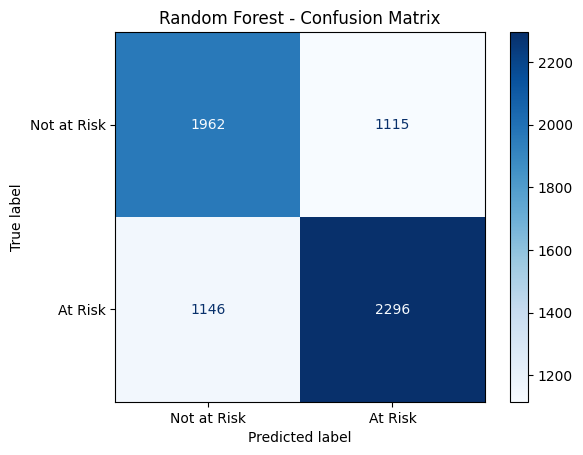

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Not at Risk", "At Risk"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Neural Network (3 Features)",
        "Accuracy": 0.6519,
        "Precision": 0.6868,
        "Recall": 0.6264,
        "F1-Score": 0.6552
    },
    {
        "Model": "Neural Network (5 Features)",
        "Accuracy": 0.6519,
        "Precision": 0.6901,
        "Recall": 0.6185,
        "F1-Score": 0.6524
    },
    {
        "Model": "Random Forest (5 Features)",
        "Accuracy": 0.6532,
        "Precision": 0.6731,
        "Recall": 0.6671,
        "F1-Score": 0.6701
    }
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network (3 Features),0.6519,0.6868,0.6264,0.6552
1,Neural Network (5 Features),0.6519,0.6901,0.6185,0.6524
2,Random Forest (5 Features),0.6532,0.6731,0.6671,0.6701


In [ ]:
report_intro = """
# Early Prediction of At-Risk Students Using Learning Analytics

## 1. Introduction

Student disengagement and course withdrawal are important
challenges in online education. Learning analytics can help
identify students who may fail or withdraw by examining
their early engagement with online learning resources.

This project uses the Open University Learning Analytics
Dataset (OULAD) to investigate whether student activity
during the first four weeks can help predict academic risk.

## 2. Research Objective

The objective is to investigate whether early online
learning activity can help predict students who are likely
to fail or withdraw from a course.

Students with final results of Fail or Withdrawn are
classified as at risk. Pass and Distinction are classified
as not at risk.

## 3. Dataset and Features

The project uses student information and Virtual Learning
Environment (VLE) activity data.

The dataset contains 32,593 student records. Early activity
features are calculated using VLE data from days 0 to 27.

The features include:
- Early total clicks
- Number of active days
- Number of unique learning sites accessed
- Clicks during weeks 1-2
- Clicks during weeks 3-4

## 4. Methodology

The data is divided into training and testing sets using
an 80:20 split, with stratification by the target class.

A Neural Network model is evaluated using three features.
A second Neural Network uses five features. A Random Forest
model is also evaluated using the five features.

Model performance is assessed using accuracy, precision,
recall, and F1-score.

## 5. Preliminary Results

The five-feature Random Forest model achieved:
- Accuracy: 65.32%
- Precision: 67.31%
- Recall: 66.71%
- F1-score: 67.01%

Among the five features, clicks during weeks 3-4 had the
highest Random Forest feature importance (approximately
25.27%).

These results are preliminary and should be interpreted
with consideration of the models' moderate predictive
performance and the overlap between activity features.
"""

print(report_intro)


# Early Prediction of At-Risk Students Using Learning Analytics

## 1. Introduction

Student disengagement and course withdrawal are important
challenges in online education. Learning analytics can help
identify students who may fail or withdraw by examining
their early engagement with online learning resources.

This project uses the Open University Learning Analytics
Dataset (OULAD) to investigate whether student activity
during the first four weeks can help predict academic risk.

## 2. Research Objective

The objective is to investigate whether early online
learning activity can help predict students who are likely
to fail or withdraw from a course.

Students with final results of Fail or Withdrawn are
classified as at risk. Pass and Distinction are classified
as not at risk.

## 3. Dataset and Features

The project uses student information and Virtual Learning
Environment (VLE) activity data.

The dataset contains 32,593 student records. Early activity
features are calculated usi

In [ ]:
from pathlib import Path

report_path = "/content/OULAD_Research_Report.md"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_intro)

print("Report saved successfully!")
print("File location:", report_path)

Report saved successfully!
File location: /content/OULAD_Research_Report.md


In [ ]:
import shutil
import os

drive_folder = "/content/drive2/MyDrive/OULAD_Project"
os.makedirs(drive_folder, exist_ok=True)

source = "/content/OULAD_Research_Report.md"
destination = drive_folder + "/OULAD_Research_Report.md"

shutil.copy(source, destination)

print("Report copied to Google Drive!")
print(destination)

Report copied to Google Drive!
/content/drive2/MyDrive/OULAD_Project/OULAD_Research_Report.md


In [ ]:
readme_text = """# Early Prediction of At-Risk Students Using Learning Analytics

## Overview
This project investigates whether early online learning activity
can help predict students who may fail or withdraw from a course.

## Dataset
The project uses the Open University Learning Analytics Dataset
(OULAD), including student information and VLE activity records.

- Student records: 32,593
- VLE activity records: approximately 10.65 million
- Early activity window: days 0-27

## Features
- Early total clicks
- Early active days
- Unique learning sites accessed
- Clicks during weeks 1-2
- Clicks during weeks 3-4

## Models
1. Neural Network with three features
2. Neural Network with five features
3. Random Forest with five features

## Preliminary Results

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Neural Network (3 features) | 65.19% | 68.68% | 62.64% | 65.52% |
| Neural Network (5 features) | 65.19% | 69.01% | 61.85% | 65.24% |
| Random Forest (5 features) | 65.32% | 67.31% | 66.71% | 67.01% |

The five-feature Random Forest achieved the highest F1-score among
these three experiments. Its overall accuracy was 65.32%, so the
predictive performance remains moderate.

## Feature Importance
The most important feature in the Random Forest model was clicks
during weeks 3-4 (approximately 25.27%).

## Limitations
The results are preliminary. The activity features overlap, and
feature importance does not establish causation. Further validation,
baseline comparisons, and careful evaluation are needed.

## Tools
- Python
- Pandas
- Scikit-learn
- Google Colab

## Research Report
See `OULAD_Research_Report.md` for the initial research report.
"""

readme_path = "/content/drive2/MyDrive/OULAD_Project/README.md"

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_text)

print("README.md saved successfully!")
print(readme_path)

README.md saved successfully!
/content/drive2/MyDrive/OULAD_Project/README.md
